# Redes Neurais Artificiais — Projeto Prático 2.1

- Redes Neurais Artificiais 2026.2
- Profa. Elloá B. Guedes (ebgcosta@uea.edu.br)
- http://github.com/elloa

### Equipe

- João Victor Mattos Lopes (github.com/Jaum36) - 2315080034
- Gabriel Augusto da Eira Corrêa Benayon (github.com/devgabrielbenayon) - 2415310049

Identificador dos exemplos: (4 + 9) % 4 = 1. 

In [5]:
# Numpy obrigatório para manipulação de arrays e matrizes
import numpy as np

import matplotlib.pyplot as plt
import random 
import math
import pandas as pd
import prettytable as pt

# Só usar pra cálculo de métrica de desempenho
#import sklearn


In [2]:
identificador = (4 + 9) % 4

dados = np.load(f"data/data{identificador}20262.txt").reshape(-1, 3)
X = dados[:, :2]
y = dados[:, 2]

# Parte I - Resolvendo um Problema Linearmente Separável

In [61]:
class Perceptron:
  def __init__(self):
    pass

  def train(self, inputs, output, taxa_aprendizado):
    self.inputs = inputs
    self.output = output
    self.taxa_aprendizado = taxa_aprendizado

    w1 = np.random.uniform(-0.5, 0.5)
    w2 = np.random.uniform(-0.5, 0.5)
    vies = np.random.uniform(-0.5, 0.5)
    epocas = 0
    qtdAjustes = 0

    while True:
      erros = 0

      epocas += 1

      for j in range(len(inputs)):
        degrau = np.where(np.asarray(((inputs[j][0] * w1) + (inputs[j][1] * w2) + vies)) >= 0, 1, 0)
        
        if output[j] != degrau:
          erros += 1
          qtdAjustes += 1

        w1 = w1 + (taxa_aprendizado * (output[j] - degrau) * inputs[j][0])
        w2 = w2 + (taxa_aprendizado * (output[j]- degrau) * inputs[j][1])
        vies = vies + (taxa_aprendizado * (output[j] - degrau))

      if erros == 0:
        break

    print(f"Números de épocas até a convergência: {epocas}")
    print(f"Número total de ajustes no vetor de pesos: {qtdAjustes}")
    return w1, w2, vies
  
  def predict(self, pesos, x1, x2):
    return 1 if (x1 * pesos[0]) + (x2 * pesos[1]) + pesos[2] >= 0 else 0


In [92]:
dados = np.load("data/dataAll20262.txt").reshape(-1, 3) 
entradas = dados[:, :2]
saida = dados[:, 2]

p = Perceptron()

pesos = p.train(entradas, saida, 0.1)

previsao = p.predict(pesos, entradas[0][0], entradas[0][1])

Números de épocas até a convergência: 3
Número total de ajustes no vetor de pesos: 41


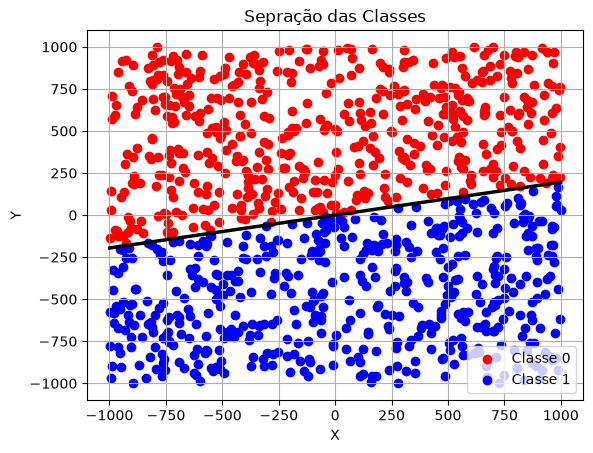

In [97]:
classe_0 = saida == 0
classe_1 = saida == 1

w1,w2,vies = pesos

plt.scatter(entradas[classe_0, 0], entradas[classe_0, 1], c='red', label="Classe 0")
plt.scatter(entradas[classe_1, 0], entradas[classe_1, 1], c='blue', label="Classe 1")

if w2 != 0:
  x1_reta = np.linspace(entradas[:, 0].min(), entradas[:, 0].max(), 200)
  x2_reta = -(w1 * x1_reta + vies) / w2
  plt.plot(x1_reta, x2_reta, color="black", linewidth=2.5)
else:
  plt.axvline(-vies / w1, color="black")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Sepração das Classes")
plt.legend()
plt.grid(True)
plt.show()